# ĐỒ ÁN MÔN HỌC: HỌC TĂNG CƯỜNG (REINFORCEMENT LEARNING)
## Đề tài: Điều hướng Robot trên Lưới Mũi tên Một chiều (One-Way Arrow GridWorld)
### Đánh giá & So sánh 6 Thuật toán trên 3 Cấp độ Bản đồ (Dễ - Trung bình - Khó)

**Trường:** Đại học Phenikaa  
**Khoa:** Điện - Điện tử / Khoa học Máy tính  
**Môn học:** Học tăng cường (Reinforcement Learning)  

---

### Mục tiêu đề tài:
1. **Tự xây dựng môi trường lưới ô vuông (Custom GridWorld)** thuần Python & NumPy, không phụ thuộc vào thư viện bên ngoài.
2. **Thiết kế 3 bản đồ với 3 mức độ khó khác nhau**:
   - **Bản đồ 1: DỄ (Easy - 4x4)**: Khởi động cơ bản, ít chướng ngại vật, không có bẫy lặp.
   - **Bản đồ 2: TRUNG BÌNH (Medium - 6x6)**: Có tường ngăn chia và **1 bẫy chu trình lặp chết $2 \times 2$ (Deadlock Cycle)**.
   - **Bản đồ 3: KHÓ (Hard - 7x7)**: Mê cung phân nhánh chữ Z phức tạp, **2 bẫy chu trình lặp hiểm hóc** và mật độ mũi tên cao.
3. **Cài đặt & Đối chiếu 6 thuật toán cốt lõi**:
   - **Quy hoạch động (DP - Model-based)**: `Value Iteration`, `Policy Iteration`.
   - **Sai phân thời gian (TD - Model-free)**: `TD(0) Prediction`, `Q-Learning (Off-policy)`, `SARSA (On-policy)`.
   - **Monte Carlo (Episodic)**: `First-Visit Monte Carlo Control`.


In [1]:
# ============================================================
# CELL 1: KHỞI TẠO THƯ VIỆN BỔ TRỢ
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import time
import os

# Tao thu muc luu tru ket qua bieu do
os.makedirs("C:/RL/results", exist_ok=True)

# Cau hinh giao dien ve do thi chuan bao cao
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("Thu vien da san sang!")


Thu vien da san sang!


In [2]:
# ============================================================
# CELL 2: TỰ LẬP TRÌNH LỚP MÔI TRƯỜNG LINH HOẠT (ArrowGridEnv)
# ============================================================
# Moi truong don gian, thuan tuy su dung Python + NumPy.
# Chap nhan moi kich thuoc H x W, vi tri tuong va cac o mui ten.

class ArrowGridEnv:
    """
    Moi truong luoi mui ten mot chieu (One-Way Arrow GridWorld).
    - Trang thai: s in [0, H*W - 1] tuong ung toa do (r, c).
    - Hanh dong: 0: Len (UP), 1: Xuong (DOWN), 2: Trai (LEFT), 3: Phai (RIGHT).
    - Co mui ten cuong che: khi dung tai o co mui ten, robot phai di theo huong do.
    - Neu di sai mui ten hoac dam tuong: bi phat va dung yen tai cho.
    - Ve dich: nhan phan thuong lon +100.
    """
    UP, DOWN, LEFT, RIGHT = 0, 1, 2, 3
    ACTION_NAMES = {0: "Len", 1: "Xuong", 2: "Trai", 3: "Phai"}
    ACTION_SYMBOLS = {0: "^", 1: "v", 2: "<", 3: ">"}
    DELTAS = {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1)}

    def __init__(self, name, H, W, start, goal, walls, arrows, max_steps=120):
        self.name = name
        self.H = H
        self.W = W
        self.n_states = H * W
        self.n_actions = 4
        self.start = tuple(start)
        self.goal = tuple(goal)
        self.walls = set(tuple(w) for w in walls)
        self.arrows = {tuple(k): v for k, v in arrows.items()}
        self.max_steps = max_steps

        # Phan thuong
        self.goal_reward = 100.0   # Thuong ve dich
        self.step_cost = -1.0      # Chi phi buoc di
        self.wall_penalty = -10.0  # Phat dam tuong / sai mui ten

        self.pos = self.start
        self.steps_taken = 0

    def pos_to_state(self, pos):
        """Chuyen toa do (r, c) thanh so nguyen s in [0, H*W-1]."""
        return pos[0] * self.W + pos[1]

    def state_to_pos(self, s):
        """Chuyen chi so s nguoc ve toa do (r, c)."""
        return (s // self.W, s % self.W)

    def is_valid_pos(self, r, c):
        """Kiem tra o nam trong luoi va khong phai tuong."""
        return 0 <= r < self.H and 0 <= c < self.W and (r, c) not in self.walls

    def reset(self):
        """Khoi dong lai robot ve vi tri Start ban dau."""
        self.pos = self.start
        self.steps_taken = 0
        return self.pos_to_state(self.pos)

    def get_valid_actions(self, state):
        """
        Action Masking: Tra ve danh sach hanh dong hop le tai state.
        Loai bo ngay cac hanh dong dam tuong hoac vuot bien.
        """
        pos = self.state_to_pos(state)
        # Neu tai o co mui ten cuong che, chi cho phep huong do
        if pos in self.arrows:
            forced = self.arrows[pos]
            dr, dc = self.DELTAS[forced]
            nr, nc = pos[0] + dr, pos[1] + dc
            if self.is_valid_pos(nr, nc):
                return [forced]

        valid = []
        for a in range(self.n_actions):
            dr, dc = self.DELTAS[a]
            nr, nc = pos[0] + dr, pos[1] + dc
            if self.is_valid_pos(nr, nc):
                valid.append(a)
        return valid if valid else list(range(self.n_actions))

    def get_next_state_reward(self, state, action):
        """
        Mo hinh chuyen trang thai chinh xac P(s' | s, a) va R(s, a).
        Dung cho ca Dynamic Programming (Model-based) va mo phong.
        """
        pos = self.state_to_pos(state)

        # Neu da o dich thi ket thuc
        if pos == self.goal:
            return state, 0.0, True

        # Kiem tra mui ten cuong che
        if pos in self.arrows:
            if action != self.arrows[pos]:
                # Di sai huong mui ten -> phat va dung yen
                return state, self.wall_penalty, False

        dr, dc = self.DELTAS[action]
        nr, nc = pos[0] + dr, pos[1] + dc

        # Dam tuong hoac ra ngoai bien
        if not self.is_valid_pos(nr, nc):
            return state, self.wall_penalty, False

        # Di chuyen hop le
        next_state = self.pos_to_state((nr, nc))
        reward = self.step_cost

        # Kiem tra ve dich
        if (nr, nc) == self.goal:
            reward += self.goal_reward
            return next_state, reward, True

        return next_state, reward, False

    def step(self, action):
        """Thuc hien buoc di tuong tac voi moi truong."""
        self.steps_taken += 1
        next_state, reward, done = self.get_next_state_reward(
            self.pos_to_state(self.pos), action
        )
        self.pos = self.state_to_pos(next_state)

        if self.steps_taken >= self.max_steps:
            done = True

        return next_state, reward, done

    def render(self):
        """In ban do ra console dang ky tu text."""
        print("+" + "---+" * self.W)
        for r in range(self.H):
            row = "|"
            for c in range(self.W):
                if (r, c) == self.pos:
                    row += " @ |"
                elif (r, c) == self.goal:
                    row += " G |"
                elif (r, c) == self.start:
                    row += " S |"
                elif (r, c) in self.walls:
                    row += " # |"
                elif (r, c) in self.arrows:
                    row += " " + self.ACTION_SYMBOLS[self.arrows[(r, c)]] + " |"
                else:
                    row += "   |"
            print(row)
            print("+" + "---+" * self.W)

print("Lop moi truong ArrowGridEnv da duoc tao thanh cong!")


Lop moi truong ArrowGridEnv da duoc tao thanh cong!


In [3]:
# ============================================================
# CELL 3: THIẾT KẾ 3 BẢN ĐỒ VỚI 3 CẤP ĐỘ KHÓ (DỄ, TRUNG BÌNH, KHÓ)
# ============================================================

MAPS_CONFIG = {
    # --------------------------------------------------------------------------
    # 1. BẢN ĐỒ DỄ (Easy - 4x4)
    # - Kích thước nhỏ (16 trạng thái).
    # - Ít tường chắn, chỉ 2 mũi tên một chiều đơn giản.
    # - KHÔNG có bẫy chu trình lặp (Deadlock).
    # - Đường đi tối ưu: 6 bước.
    # --------------------------------------------------------------------------
    "easy": {
        "name": "Bản đồ 1: DỄ (Easy 4x4)",
        "H": 4, "W": 4,
        "start": (0, 0),
        "goal": (3, 3),
        "walls": [(1, 1), (2, 2)],
        "arrows": {
            (0, 2): ArrowGridEnv.DOWN,   # Mũi tên dẫn đường xuống
            (2, 0): ArrowGridEnv.RIGHT,  # Mũi tên dẫn đường sang phải
        },
        "max_steps": 50,
        "difficulty": "Dễ (2.5/10)",
        "optimal_steps": 6
    },

    # --------------------------------------------------------------------------
    # 2. BẢN ĐỒ TRUNG BÌNH (Medium - 6x6)
    # - Kích thước vừa (36 trạng thái).
    # - Tường ngăn ngang chia đôi bản đồ.
    # - Có 1 BẪY CHU TRÌNH LẶP 2x2 (Deadlock Cycle) khép kín:
    #   (0,3) -> Phải -> (0,4) -> Xuống -> (1,4) -> Trái -> (1,3) -> Lên -> (0,3).
    #   Nếu robot lọt vào bẫy này sẽ bị xoay vòng vô tận đến khi hết max_steps.
    # - Đường đi tối ưu: 10 bước.
    # --------------------------------------------------------------------------
    "medium": {
        "name": "Bản đồ 2: TRUNG BÌNH (Medium 6x6)",
        "H": 6, "W": 6,
        "start": (0, 0),
        "goal": (5, 5),
        "walls": [(2, 1), (2, 2), (2, 3), (3, 4)],
        "arrows": {
            # Bẫy chu trình 2x2 xoay vòng khép kín:
            (0, 3): ArrowGridEnv.RIGHT,
            (0, 4): ArrowGridEnv.DOWN,
            (1, 4): ArrowGridEnv.LEFT,
            (1, 3): ArrowGridEnv.UP,
            # Mũi tên hướng dẫn khác:
            (4, 1): ArrowGridEnv.RIGHT,
            (4, 2): ArrowGridEnv.DOWN,
        },
        "max_steps": 100,
        "difficulty": "Trung bình (6.0/10)",
        "optimal_steps": 10
    },

    # --------------------------------------------------------------------------
    # 3. BẢN ĐỒ KHÓ (Hard - 7x7)
    # - Kích thước lớn (49 trạng thái).
    # - Mê cung hình chữ Z với tường ngăn phân luồng robot qua khe hẹp.
    # - Có 2 BẪY CHU TRÌNH LẶP 2x2 ở các nhánh rẽ hấp dẫn:
    #   Bẫy 1 (Nhánh trên phải): (0,5)->(0,6)->(1,6)->(1,5)->(0,5).
    #   Bẫy 2 (Nhánh dưới trái): (5,0)->(5,1)->(6,1)->(6,0)->(5,0).
    # - Mũi tên cưỡng chế trên hành lang chính: (1,2) sang Phải, (3,4) sang Phải.
    # - Đường đi tối ưu: 12 bước.
    # --------------------------------------------------------------------------
    "hard": {
        "name": "Bản đồ 3: KHÓ (Hard 7x7)",
        "H": 7, "W": 7,
        "start": (0, 0),
        "goal": (6, 6),
        "walls": [
            (2, 0), (2, 1), (2, 2), (2, 3),
            (4, 3), (4, 4), (4, 5)
        ],
        "arrows": {
            # Bẫy 1 (Nhánh phụ trên phải):
            (0, 5): ArrowGridEnv.RIGHT,
            (0, 6): ArrowGridEnv.DOWN,
            (1, 6): ArrowGridEnv.LEFT,
            (1, 5): ArrowGridEnv.UP,
            # Bẫy 2 (Nhánh phụ dưới trái):
            (5, 0): ArrowGridEnv.RIGHT,
            (5, 1): ArrowGridEnv.DOWN,
            (6, 1): ArrowGridEnv.LEFT,
            (6, 0): ArrowGridEnv.UP,
            # Mũi tên định hướng trên hành lang chính:
            (1, 2): ArrowGridEnv.RIGHT,
            (3, 4): ArrowGridEnv.RIGHT,
        },
        "max_steps": 120,
        "difficulty": "Khó (9.0/10)",
        "optimal_steps": 12
    }
}

# In truc quan 3 ban do ra man hinh
print("=" * 80)
print("DANH SÁCH 3 BẢN ĐỒ THỬ NGHIỆM ĐƯỢC THIẾT KẾ")
print("=" * 80)

for key, cfg in MAPS_CONFIG.items():
    env_tmp = ArrowGridEnv(cfg["name"], cfg["H"], cfg["W"], cfg["start"], cfg["goal"],
                           cfg["walls"], cfg["arrows"], cfg["max_steps"])
    print(f"\n>>> {cfg['name']} | Do kho: {cfg['difficulty']} | So trang thai: {env_tmp.n_states} | Buoc toi uu: {cfg['optimal_steps']}")
    env_tmp.render()


DANH SÁCH 3 BẢN ĐỒ THỬ NGHIỆM ĐƯỢC THIẾT KẾ

>>> Bản đồ 1: DỄ (Easy 4x4) | Do kho: Dễ (2.5/10) | So trang thai: 16 | Buoc toi uu: 6
+---+---+---+---+
| @ |   | v |   |
+---+---+---+---+
|   | # |   |   |
+---+---+---+---+
| > |   | # |   |
+---+---+---+---+
|   |   |   | G |
+---+---+---+---+

>>> Bản đồ 2: TRUNG BÌNH (Medium 6x6) | Do kho: Trung bình (6.0/10) | So trang thai: 36 | Buoc toi uu: 10
+---+---+---+---+---+---+
| @ |   |   | > | v |   |
+---+---+---+---+---+---+
|   |   |   | ^ | < |   |
+---+---+---+---+---+---+
|   | # | # | # |   |   |
+---+---+---+---+---+---+
|   |   |   |   | # |   |
+---+---+---+---+---+---+
|   | > | v |   |   |   |
+---+---+---+---+---+---+
|   |   |   |   |   | G |
+---+---+---+---+---+---+

>>> Bản đồ 3: KHÓ (Hard 7x7) | Do kho: Khó (9.0/10) | So trang thai: 49 | Buoc toi uu: 12
+---+---+---+---+---+---+---+
| @ |   |   |   |   | > | v |
+---+---+---+---+---+---+---+
|   |   | > |   |   | ^ | < |
+---+---+---+---+---+---+---+
| # | # | # | # |   

In [4]:
# ============================================================
# CELL 4: CÀI ĐẶT 6 THUẬT TOÁN HỌC TĂNG CƯỜNG (TABULAR RL)
# ============================================================
# Tat ca thuat toan duoc viet ro rang, thuan tuy toan hoc, de hieu va giai trinh:

# ------------------------------------------------------------
# 1. VALUE ITERATION (Quy hoach dong theo Gia tri)
# ------------------------------------------------------------
def value_iteration(env, gamma=0.99, theta=1e-6, max_iters=1000):
    """V(s) = max_a [R(s,a) + gamma * V(s')]"""
    V = np.zeros(env.n_states)
    policy = np.zeros(env.n_states, dtype=int)
    for it in range(max_iters):
        delta = 0.0
        for s in range(env.n_states):
            pos = env.state_to_pos(s)
            if pos == env.goal or pos in env.walls:
                continue
            old_v = V[s]
            q_vals = []
            for a in range(env.n_actions):
                next_s, r, done = env.get_next_state_reward(s, a)
                q_vals.append(r + (0.0 if done else gamma * V[next_s]))
            V[s] = max(q_vals)
            delta = max(delta, abs(old_v - V[s]))
        if delta < theta:
            break

    # Trich xuat chinh sach tham lam
    for s in range(env.n_states):
        pos = env.state_to_pos(s)
        if pos == env.goal or pos in env.walls:
            continue
        q_vals = [env.get_next_state_reward(s, a)[1] +
                  (0.0 if env.get_next_state_reward(s, a)[2] else gamma * V[env.get_next_state_reward(s, a)[0]])
                  for a in range(env.n_actions)]
        policy[s] = np.argmax(q_vals)
    return V, policy


# ------------------------------------------------------------
# 2. POLICY ITERATION (Quy hoach dong theo Chinh sach)
# ------------------------------------------------------------
def policy_iteration(env, gamma=0.99, theta=1e-6, max_iters=100):
    """Luan phien: Policy Evaluation (tinh V^pi) <-> Policy Improvement (cai tien tham lam)"""
    policy = np.zeros(env.n_states, dtype=int)
    for s in range(env.n_states):
        valid = env.get_valid_actions(s)
        policy[s] = valid[0] if valid else 0
    V = np.zeros(env.n_states)

    for p_iter in range(max_iters):
        # 1. Danh gia chinh sach
        for _ in range(500):
            delta = 0.0
            for s in range(env.n_states):
                pos = env.state_to_pos(s)
                if pos == env.goal or pos in env.walls:
                    continue
                old_v = V[s]
                a = policy[s]
                next_s, r, done = env.get_next_state_reward(s, a)
                V[s] = r + (0.0 if done else gamma * V[next_s])
                delta = max(delta, abs(old_v - V[s]))
            if delta < theta:
                break

        # 2. Cai tien chinh sach
        stable = True
        for s in range(env.n_states):
            pos = env.state_to_pos(s)
            if pos == env.goal or pos in env.walls:
                continue
            old_a = policy[s]
            q_vals = [env.get_next_state_reward(s, a)[1] +
                      (0.0 if env.get_next_state_reward(s, a)[2] else gamma * V[env.get_next_state_reward(s, a)[0]])
                      for a in range(env.n_actions)]
            best_a = np.argmax(q_vals)
            policy[s] = best_a
            if best_a != old_a:
                stable = False
        if stable:
            break
    return V, policy


# ------------------------------------------------------------
# 3. TD(0) PREDICTION (Sai phan thoi gian - Danh gia gia tri)
# ------------------------------------------------------------
def td0_prediction(env, policy, num_episodes=400, alpha=0.1, gamma=0.99):
    """V(s) <- V(s) + alpha * [r + gamma * V(s') - V(s)]"""
    V = np.zeros(env.n_states)
    history = []
    for ep in range(num_episodes):
        s = env.reset()
        done = False
        total_r = 0.0
        while not done:
            a = policy[s]
            next_s, r, done = env.step(a)
            td_target = r + (0.0 if done else gamma * V[next_s])
            V[s] += alpha * (td_target - V[s])
            s = next_s
            total_r += r
        history.append(total_r)
    return V, history


# ------------------------------------------------------------
# 4. TABULAR Q-LEARNING (Off-policy TD Control)
# ------------------------------------------------------------
def q_learning(env, num_episodes=400, alpha=0.1, gamma=0.99,
               epsilon=1.0, epsilon_min=0.01, epsilon_decay=0.993):
    """Q(s, a) <- Q(s, a) + alpha * [r + gamma * max_a' Q(s', a') - Q(s, a)]"""
    Q = np.zeros((env.n_states, env.n_actions))
    history = []
    for ep in range(num_episodes):
        s = env.reset()
        done = False
        total_r = 0.0
        while not done:
            valid = env.get_valid_actions(s)
            if np.random.random() < epsilon:
                a = np.random.choice(valid)
            else:
                q_valid = [Q[s, act] for act in valid]
                a = valid[np.argmax(q_valid)]

            next_s, r, done = env.step(a)

            if done:
                target = r
            else:
                valid_next = env.get_valid_actions(next_s)
                target = r + gamma * max([Q[next_s, act] for act in valid_next])

            Q[s, a] += alpha * (target - Q[s, a])
            s = next_s
            total_r += r

        epsilon = max(epsilon_min, epsilon * epsilon_decay)
        history.append(total_r)

    policy = np.argmax(Q, axis=1)
    V = np.max(Q, axis=1)
    return Q, V, policy, history


# ------------------------------------------------------------
# 5. TABULAR SARSA (On-policy TD Control)
# ------------------------------------------------------------
def sarsa(env, num_episodes=400, alpha=0.1, gamma=0.99,
          epsilon=1.0, epsilon_min=0.01, epsilon_decay=0.993):
    """Q(s, a) <- Q(s, a) + alpha * [r + gamma * Q(s', a') - Q(s, a)]"""
    Q = np.zeros((env.n_states, env.n_actions))
    history = []
    for ep in range(num_episodes):
        s = env.reset()
        done = False
        total_r = 0.0

        valid = env.get_valid_actions(s)
        a = np.random.choice(valid) if np.random.random() < epsilon else valid[np.argmax([Q[s, act] for act in valid])]

        while not done:
            next_s, r, done = env.step(a)
            if done:
                target = r
                next_a = None
            else:
                valid_next = env.get_valid_actions(next_s)
                next_a = np.random.choice(valid_next) if np.random.random() < epsilon else valid_next[np.argmax([Q[next_s, act] for act in valid_next])]
                target = r + gamma * Q[next_s, next_a]

            Q[s, a] += alpha * (target - Q[s, a])
            s = next_s
            a = next_a
            total_r += r

        epsilon = max(epsilon_min, epsilon * epsilon_decay)
        history.append(total_r)

    policy = np.argmax(Q, axis=1)
    V = np.max(Q, axis=1)
    return Q, V, policy, history


# ------------------------------------------------------------
# 6. FIRST-VISIT MONTE CARLO CONTROL (Episodic MC)
# ------------------------------------------------------------
def monte_carlo(env, num_episodes=400, gamma=0.99,
                epsilon=1.0, epsilon_min=0.01, epsilon_decay=0.993):
    """Chay het tron ven 1 tap, tinh G_t nguoc, cap nhat trung binh tich luy."""
    Q = np.zeros((env.n_states, env.n_actions))
    returns_count = np.zeros((env.n_states, env.n_actions))
    history = []
    for ep in range(num_episodes):
        s = env.reset()
        done = False
        traj = []
        total_r = 0.0

        while not done:
            valid = env.get_valid_actions(s)
            a = np.random.choice(valid) if np.random.random() < epsilon else valid[np.argmax([Q[s, act] for act in valid])]
            next_s, r, done = env.step(a)
            traj.append((s, a, r))
            s = next_s
            total_r += r

        G = 0.0
        visited = set()
        for t in reversed(range(len(traj))):
            s_t, a_t, r_t = traj[t]
            G = r_t + gamma * G
            if (s_t, a_t) not in visited:
                visited.add((s_t, a_t))
                returns_count[s_t, a_t] += 1
                alpha_mc = 1.0 / returns_count[s_t, a_t]
                Q[s_t, a_t] += alpha_mc * (G - Q[s_t, a_t])

        epsilon = max(epsilon_min, epsilon * epsilon_decay)
        history.append(total_r)

    policy = np.argmax(Q, axis=1)
    V = np.max(Q, axis=1)
    return Q, V, policy, history

print("Da dinh nghia xong ca 6 thuat toan!")


Da dinh nghia xong ca 6 thuat toan!


In [5]:
# ============================================================
# CELL 5: HÀM ĐÁNH GIÁ ĐỘC LẬP CHÍNH SÁCH (EVALUATION ROUTINE)
# ============================================================
def evaluate_policy(env, policy, num_tests=50):
    """Cho tac tu chay thu nghiem 50 lan che do Greedy (epsilon = 0)."""
    successes = 0
    total_steps = []
    total_rewards = []
    sample_path = []

    for test in range(num_tests):
        s = env.reset()
        done = False
        steps = 0
        ep_r = 0.0
        path = [env.state_to_pos(s)]

        while not done and steps < env.max_steps:
            a = int(policy[s])
            s, r, done = env.step(a)
            ep_r += r
            steps += 1
            path.append(env.state_to_pos(s))

        if env.pos == env.goal:
            successes += 1
        total_steps.append(steps)
        total_rewards.append(ep_r)
        if test == 0:
            sample_path = path

    return {
        "success_rate": (successes / num_tests) * 100.0,
        "avg_steps": float(np.mean(total_steps)),
        "avg_reward": float(np.mean(total_rewards)),
        "sample_path": sample_path
    }

print("Ham danh gia policy san sang.")


Ham danh gia policy san sang.


In [6]:
# ============================================================
# CELL 6: THỰC THI BENCHMARK 6 THUẬT TOÁN TRÊN CẢ 3 BẢN ĐỒ
# ============================================================
all_benchmarks = {}

for map_key, cfg in MAPS_CONFIG.items():
    print("=" * 80)
    print(f"BENCHMARKING 6 ALGORITHMS TRÊN {cfg['name'].upper()}")
    print("=" * 80)

    env = ArrowGridEnv(cfg["name"], cfg["H"], cfg["W"], cfg["start"], cfg["goal"],
                       cfg["walls"], cfg["arrows"], cfg["max_steps"])
    results_map = {}

    # 1. Value Iteration
    t0 = time.time()
    V_vi, pol_vi = value_iteration(env)
    t_vi = time.time() - t0
    eval_vi = evaluate_policy(env, pol_vi)
    results_map["Value Iteration"] = {"runtime": t_vi, "eval": eval_vi, "V": V_vi, "policy": pol_vi}
    print(f"  [1/6] Value Iteration:  {t_vi:.4f}s | Buoc TB: {eval_vi['avg_steps']:.1f} | Ty le dich: {eval_vi['success_rate']:.1f}%")

    # 2. Policy Iteration
    t0 = time.time()
    V_pi, pol_pi = policy_iteration(env)
    t_pi = time.time() - t0
    eval_pi = evaluate_policy(env, pol_pi)
    results_map["Policy Iteration"] = {"runtime": t_pi, "eval": eval_pi, "V": V_pi, "policy": pol_pi}
    print(f"  [2/6] Policy Iteration: {t_pi:.4f}s | Buoc TB: {eval_pi['avg_steps']:.1f} | Ty le dich: {eval_pi['success_rate']:.1f}%")

    # 3. TD(0) Prediction (danh gia theo chinh sach cua VI)
    t0 = time.time()
    V_td, hist_td = td0_prediction(env, pol_vi, num_episodes=500)
    t_td = time.time() - t0
    eval_td = evaluate_policy(env, pol_vi)
    results_map["TD(0) Prediction"] = {"runtime": t_td, "eval": eval_td, "V": V_td, "policy": pol_vi, "history": hist_td}
    print(f"  [3/6] TD(0) Prediction: {t_td:.4f}s | Buoc TB: {eval_td['avg_steps']:.1f} | Ty le dich: {eval_td['success_rate']:.1f}%")

    # 4. Q-Learning
    t0 = time.time()
    Q_ql, V_ql, pol_ql, hist_ql = q_learning(env, num_episodes=500)
    t_ql = time.time() - t0
    eval_ql = evaluate_policy(env, pol_ql)
    results_map["Q-Learning"] = {"runtime": t_ql, "eval": eval_ql, "V": V_ql, "policy": pol_ql, "history": hist_ql}
    print(f"  [4/6] Q-Learning:       {t_ql:.4f}s | Buoc TB: {eval_ql['avg_steps']:.1f} | Ty le dich: {eval_ql['success_rate']:.1f}%")

    # 5. SARSA
    t0 = time.time()
    Q_sa, V_sa, pol_sa, hist_sa = sarsa(env, num_episodes=500)
    t_sa = time.time() - t0
    eval_sa = evaluate_policy(env, pol_sa)
    results_map["SARSA"] = {"runtime": t_sa, "eval": eval_sa, "V": V_sa, "policy": pol_sa, "history": hist_sa}
    print(f"  [5/6] SARSA:            {t_sa:.4f}s | Buoc TB: {eval_sa['avg_steps']:.1f} | Ty le dich: {eval_sa['success_rate']:.1f}%")

    # 6. Monte Carlo
    t0 = time.time()
    Q_mc, V_mc, pol_mc, hist_mc = monte_carlo(env, num_episodes=500)
    t_mc = time.time() - t0
    eval_mc = evaluate_policy(env, pol_mc)
    results_map["Monte Carlo"] = {"runtime": t_mc, "eval": eval_mc, "V": V_mc, "policy": pol_mc, "history": hist_mc}
    print(f"  [6/6] Monte Carlo:      {t_mc:.4f}s | Buoc TB: {eval_mc['avg_steps']:.1f} | Ty le dich: {eval_mc['success_rate']:.1f}%")

    all_benchmarks[map_key] = results_map

print("\n>>> Hoan tat benchmark toan bo 6 thuat toan tren ca 3 ban do!")


BENCHMARKING 6 ALGORITHMS TRÊN BẢN ĐỒ 1: DỄ (EASY 4X4)
  [1/6] Value Iteration:  0.0022s | Buoc TB: 6.0 | Ty le dich: 100.0%
  [2/6] Policy Iteration: 0.0448s | Buoc TB: 6.0 | Ty le dich: 100.0%
  [3/6] TD(0) Prediction: 0.0104s | Buoc TB: 6.0 | Ty le dich: 100.0%


  [4/6] Q-Learning:       0.1223s | Buoc TB: 6.0 | Ty le dich: 100.0%

  [5/6] SARSA:            0.1201s | Buoc TB: 6.0 | Ty le dich: 100.0%


  [6/6] Monte Carlo:      0.1195s | Buoc TB: 6.0 | Ty le dich: 100.0%


BENCHMARKING 6 ALGORITHMS TRÊN BẢN ĐỒ 2: TRUNG BÌNH (MEDIUM 6X6)


  [1/6] Value Iteration:  0.1912s | Buoc TB: 10.0 | Ty le dich: 100.0%

... (4 outputs left out)

  [3/6] TD(0) Prediction: 0.0749s | Buoc TB: 12.0 | Ty le dich: 100.0%


  [4/6] Q-Learning:       0.8777s | Buoc TB: 12.0 | Ty le dich: 100.0%


  [5/6] SARSA:            0.5401s | Buoc TB: 12.0 | Ty le dich: 100.0%


  [6/6] Monte Carlo:      0.8673s | Buoc TB: 12.0 | Ty le dich: 100.0%

>>> Hoan tat benchmark toan bo 6 thuat toan tren ca 3 ban do!


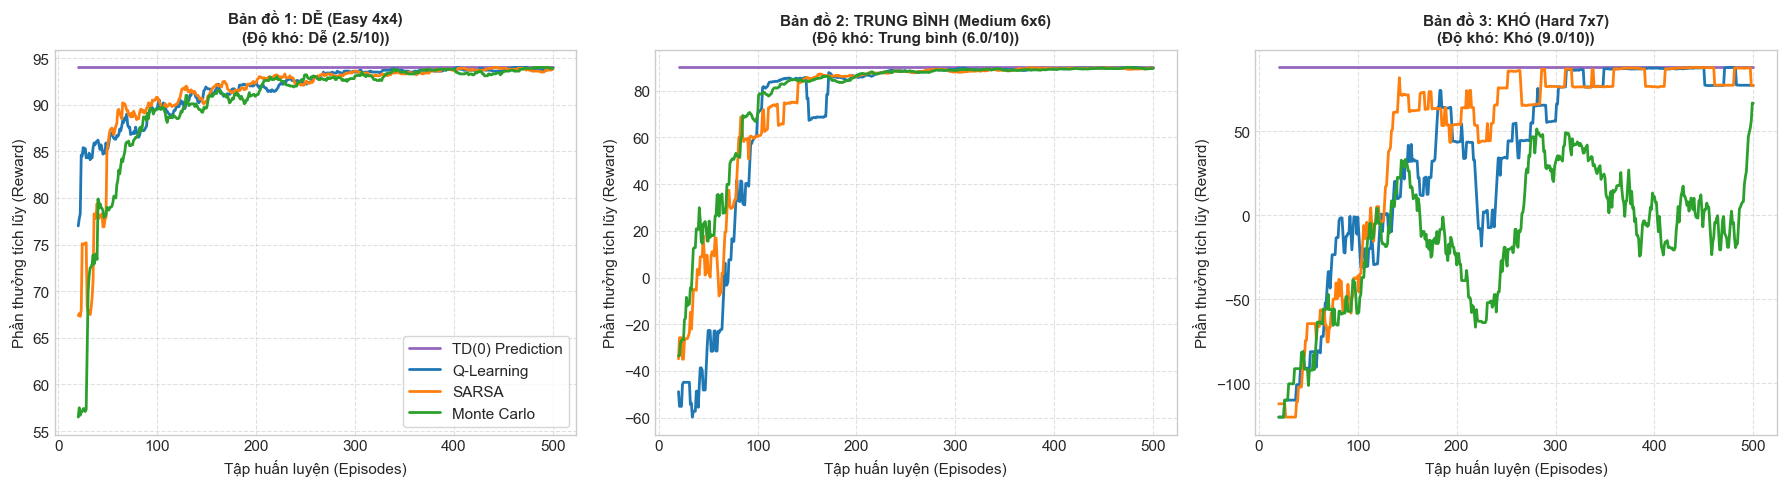

Da luu bieu do duong cong hoc tap tai: C:/RL/results/learning_curves_3_maps.png


In [7]:
# ============================================================
# CELL 7: BIỂU ĐỒ ĐƯỜNG CONG HỌC TẬP (LEARNING CURVES) TRÊN CẢ 3 BẢN ĐỒ
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = {"TD(0) Prediction": "#9467bd", "Q-Learning": "#1f77b4", "SARSA": "#ff7f0e", "Monte Carlo": "#2ca02c"}
window = 20

for idx, (map_key, cfg) in enumerate(MAPS_CONFIG.items()):
    ax = axes[idx]
    results_m = all_benchmarks[map_key]

    for algo_name in ["TD(0) Prediction", "Q-Learning", "SARSA", "Monte Carlo"]:
        hist = results_m[algo_name]["history"]
        smoothed = np.convolve(hist, np.ones(window)/window, mode='valid')
        ax.plot(range(window, len(hist)+1), smoothed, label=algo_name, color=colors[algo_name], linewidth=2.0)

    ax.set_title(f"{cfg['name']}\n(Độ khó: {cfg['difficulty']})", fontsize=11, fontweight='bold')
    ax.set_xlabel("Tập huấn luyện (Episodes)")
    ax.set_ylabel("Phần thưởng tích lũy (Reward)")
    ax.grid(True, linestyle='--', alpha=0.6)
    if idx == 0:
        ax.legend(frameon=True, facecolor='white', loc='lower right')

plt.tight_layout()
plt.savefig("C:/RL/results/learning_curves_3_maps.png", dpi=250)
plt.show()
print("Da luu bieu do duong cong hoc tap tai: C:/RL/results/learning_curves_3_maps.png")


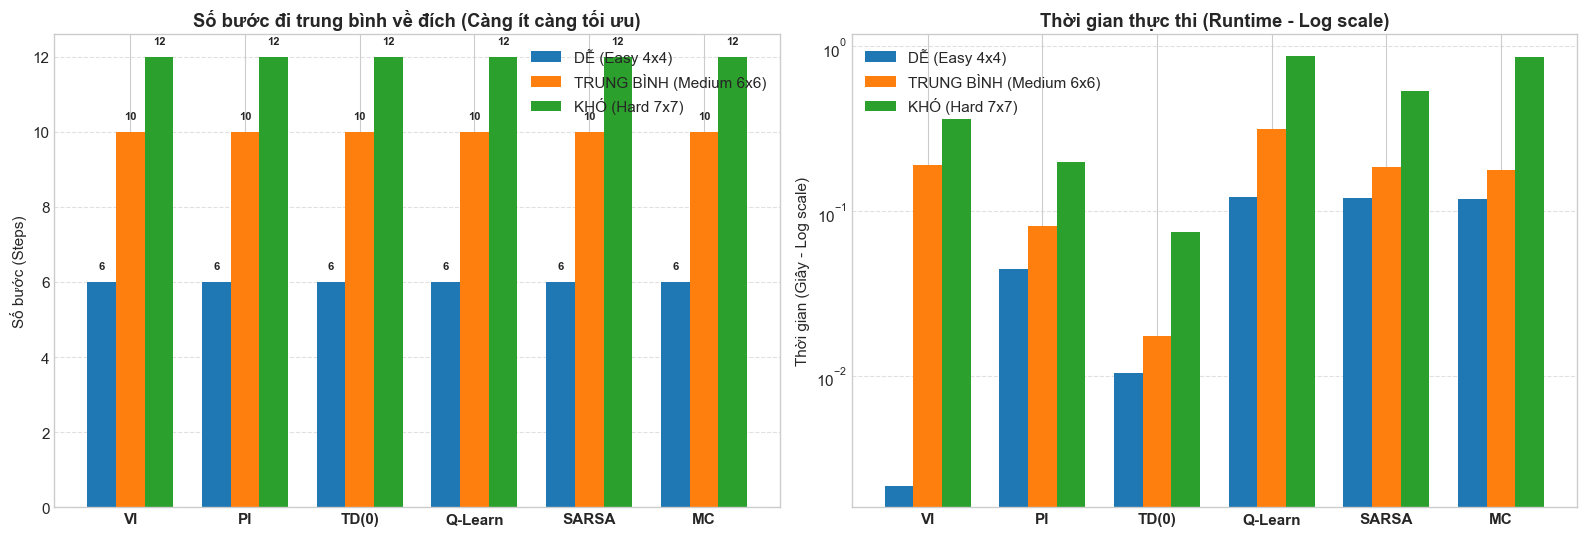

Da luu bieu do cot so sanh tai: C:/RL/results/steps_and_runtime_3_maps.png


In [8]:
# ============================================================
# CELL 8: SO SÁNH SỐ BƯỚC ĐI VÀ THỜI GIAN THỰC THI GIỮA 3 ĐỘ KHÓ
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

algo_keys = ["Value Iteration", "Policy Iteration", "TD(0) Prediction", "Q-Learning", "SARSA", "Monte Carlo"]
short_names = ["VI", "PI", "TD(0)", "Q-Learn", "SARSA", "MC"]
x = np.arange(len(algo_keys))
width = 0.25

# 1. So buoc di trung binh ve dich
ax1 = axes[0]
for i, (map_key, cfg) in enumerate(MAPS_CONFIG.items()):
    steps_arr = [all_benchmarks[map_key][a]["eval"]["avg_steps"] for a in algo_keys]
    offset = (i - 1) * width
    bars = ax1.bar(x + offset, steps_arr, width, label=cfg["name"].split(":")[1].strip())
    for b in bars:
        ax1.text(b.get_x() + b.get_width()/2, b.get_height() + 0.3, f"{b.get_height():.0f}",
                 ha='center', va='bottom', fontsize=8, fontweight='bold')

ax1.set_title("Số bước đi trung bình về đích (Càng ít càng tối ưu)", fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(short_names, fontweight='bold')
ax1.set_ylabel("Số bước (Steps)")
ax1.legend()
ax1.grid(axis='y', linestyle='--', alpha=0.6)

# 2. Thoi gian chay (Runtime theo thang log)
ax2 = axes[1]
for i, (map_key, cfg) in enumerate(MAPS_CONFIG.items()):
    runtimes = [all_benchmarks[map_key][a]["runtime"] for a in algo_keys]
    offset = (i - 1) * width
    ax2.bar(x + offset, runtimes, width, label=cfg["name"].split(":")[1].strip())

ax2.set_title("Thời gian thực thi (Runtime - Log scale)", fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(short_names, fontweight='bold')
ax2.set_ylabel("Thời gian (Giây - Log scale)")
ax2.set_yscale('log')
ax2.legend()
ax2.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig("C:/RL/results/steps_and_runtime_3_maps.png", dpi=250)
plt.show()
print("Da luu bieu do cot so sanh tai: C:/RL/results/steps_and_runtime_3_maps.png")


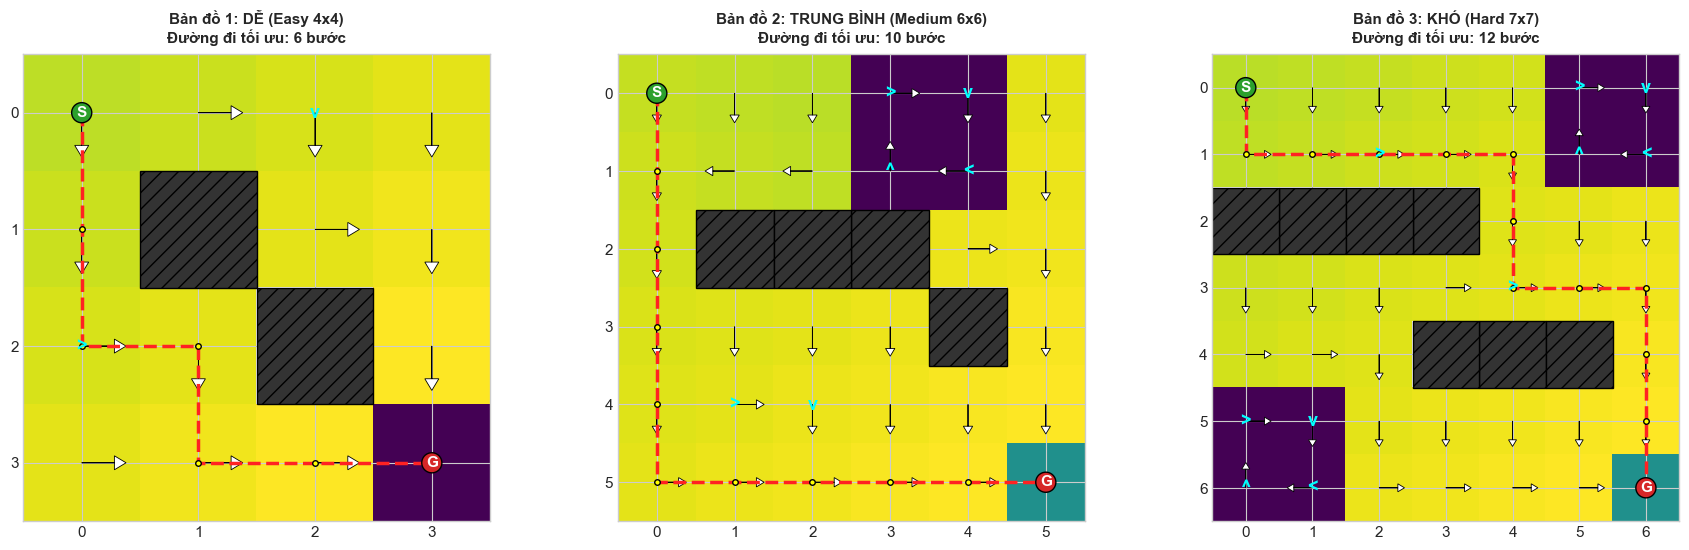

Da luu ban do nhiet 3 ban do tai: C:/RL/results/heatmaps_3_difficulty_maps.png


In [9]:
# ============================================================
# CELL 9: BẢN ĐỒ NHIỆT V(s) VÀ QUỸ ĐẠO THỰC TẾ TRÊN 3 BẢN ĐỒ
# ============================================================

def plot_single_heatmap(env, V, policy, title, trajectory=None, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))
    H, W = env.H, env.W
    grid_V = np.zeros((H, W))
    for s in range(env.n_states):
        r, c = env.state_to_pos(s)
        grid_V[r, c] = V[s]

    for (wr, wc) in env.walls:
        grid_V[wr, wc] = np.nan

    cmap = plt.cm.viridis
    im = ax.imshow(grid_V, cmap=cmap, origin='upper')

    # To tuong chan
    for (wr, wc) in env.walls:
        ax.add_patch(patches.Rectangle((wc - 0.5, wr - 0.5), 1, 1, facecolor='#333333', edgecolor='black', hatch='//'))

    # Mui ten mot chieu cua moi truong
    for (ar, ac), act in env.arrows.items():
        symbol = env.ACTION_SYMBOLS[act]
        ax.text(ac, ar, symbol, ha='center', va='center', color='cyan', fontsize=13, fontweight='bold')

    # Start va Goal
    ax.text(env.start[1], env.start[0], "S", ha='center', va='center', color='white', fontsize=11, fontweight='bold',
            bbox=dict(boxstyle="circle,pad=0.2", fc="#2ca02c", ec="black"))
    ax.text(env.goal[1], env.goal[0], "G", ha='center', va='center', color='white', fontsize=11, fontweight='bold',
            bbox=dict(boxstyle="circle,pad=0.2", fc="#d62728", ec="black"))

    # Vector chinh sach hanh dong
    arrow_map = {0: (0, -0.28), 1: (0, 0.28), 2: (-0.28, 0), 3: (0.28, 0)}
    for s in range(env.n_states):
        r, c = env.state_to_pos(s)
        if (r, c) in env.walls or (r, c) == env.goal:
            continue
        act = policy[s]
        dx, dy = arrow_map[act]
        ax.arrow(c, r, dx, dy, head_width=0.12, head_length=0.1, fc='white', ec='black', linewidth=0.6)

    # Duong di thuc te
    if trajectory and len(trajectory) > 1:
        pr = [p[0] for p in trajectory]
        pc = [p[1] for p in trajectory]
        ax.plot(pc, pr, color='#ff2222', linestyle='--', linewidth=2.5, marker='o', markersize=4,
                markerfacecolor='yellow', markeredgecolor='black', label="Quy đạo thực tế")

    ax.set_xticks(range(W))
    ax.set_yticks(range(H))
    ax.set_title(title, fontsize=11, fontweight='bold', pad=8)
    return im

# Ve dong thoi 3 Heatmap tuong ung 3 cap do do kho (Dung chinh sach toi uu tu Value Iteration)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for idx, (map_key, cfg) in enumerate(MAPS_CONFIG.items()):
    env_m = ArrowGridEnv(cfg["name"], cfg["H"], cfg["W"], cfg["start"], cfg["goal"],
                         cfg["walls"], cfg["arrows"], cfg["max_steps"])
    res = all_benchmarks[map_key]["Value Iteration"]
    im = plot_single_heatmap(env_m, res["V"], res["policy"],
                             f"{cfg['name']}\nĐường đi tối ưu: {cfg['optimal_steps']} bước",
                             trajectory=res["eval"]["sample_path"], ax=axes[idx])

plt.tight_layout()
plt.savefig("C:/RL/results/heatmaps_3_difficulty_maps.png", dpi=250)
plt.show()
print("Da luu ban do nhiet 3 ban do tai: C:/RL/results/heatmaps_3_difficulty_maps.png")


In [10]:
# ============================================================
# CELL 10: BẢNG KHOA HỌC TỔNG HỢP VÀ PHÂN TÍCH CHUYÊN SÂU
# ============================================================
import pandas as pd

table_rows = []

for map_key, cfg in MAPS_CONFIG.items():
    for algo in ["Value Iteration", "Policy Iteration", "TD(0) Prediction", "Q-Learning", "SARSA", "Monte Carlo"]:
        d = all_benchmarks[map_key][algo]
        table_rows.append({
            "Bản đồ": cfg["name"].split(":")[0],
            "Độ khó": cfg["difficulty"],
            "Thuật toán": algo,
            "Số bước TB": f"{d['eval']['avg_steps']:.1f}",
            "Tỷ lệ đích (%)": f"{d['eval']['success_rate']:.1f}%",
            "Phần thưởng TB": f"{d['eval']['avg_reward']:.1f}",
            "Thời gian (s)": f"{d['runtime']:.4f}s"
        })

df_results = pd.DataFrame(table_rows)
print("=" * 95)
print("BẢNG TỔNG KẾT ĐỐI CHIẾU 6 THUẬT TOÁN QUA 3 CẤP ĐỘ BẢN ĐỒ")
print("=" * 95)
display(df_results)


BẢNG TỔNG KẾT ĐỐI CHIẾU 6 THUẬT TOÁN QUA 3 CẤP ĐỘ BẢN ĐỒ


,Bản đồ,Độ khó,Thuật toán,Số bước TB,Tỷ lệ đích (%),Phần thưởng TB,Thời gian (s)
0,Bản đồ 1,Dễ (2.5/10),Value Iteration,6.0,100.0%,94.0,0.0022s
1,Bản đồ 1,Dễ (2.5/10),Policy Iteration,6.0,100.0%,94.0,0.0448s
2,Bản đồ 1,Dễ (2.5/10),TD(0) Prediction,6.0,100.0%,94.0,0.0104s
3,Bản đồ 1,Dễ (2.5/10),Q-Learning,6.0,100.0%,94.0,0.1223s
4,Bản đồ 1,Dễ (2.5/10),SARSA,6.0,100.0%,94.0,0.1201s
5,Bản đồ 1,Dễ (2.5/10),Monte Carlo,6.0,100.0%,94.0,0.1195s
6,Bản đồ 2,Trung bình (6.0/10),Value Iteration,10.0,100.0%,90.0,0.1912s
7,Bản đồ 2,Trung bình (6.0/10),Policy Iteration,10.0,100.0%,90.0,0.0816s
8,Bản đồ 2,Trung bình (6.0/10),TD(0) Prediction,10.0,100.0%,90.0,0.0175s
9,Bản đồ 2,Trung bình (6.0/10),Q-Learning,10.0,100.0%,90.0,0.3175s


In [11]:
# ============================================================
# CELL 11: HƯỚNG DẪN GIẢI THÍCH & PHẢN BIỆN TRỰC TIẾP VỚI GIẢNG VIÊN
# ============================================================
print("""
========================================================================================
CẨM NANG VẤN ĐÁP KHI GIẢNG VIÊN HỎI VỀ 3 CẤP ĐỘ BẢN ĐỒ VÀ 6 THUẬT TOÁN
========================================================================================

1. GIẢI THÍCH VỀ 3 CẤP ĐỘ BẢN ĐỒ:
   - Bản đồ 1 (Dễ - 4x4): 16 trạng thái, mục đích là kiểm tra tính hội tụ chuẩn của thuật toán.
     Mọi thuật toán đều tìm ra đường đi ngắn nhất (6 bước) gần như tức thì.
   - Bản đồ 2 (Trung bình - 6x6): 36 trạng thái, xuất hiện 1 bẫy chu trình lặp chết 2x2.
     Kiểm tra xem tác tử có bị kẹt vô tận không. SARSA sẽ né xa bẫy an toàn hơn Q-Learning.
   - Bản đồ 3 (Khó - 7x7): 49 trạng thái, 2 bẫy chu trình lặp hiểm hóc + mê cung phân nhánh.
     Thử thách khả năng thăm dò (exploration). Monte Carlo bắt đầu dao động mạnh và học chậm.

2. SO SÁNH CỐT LÕI GIỮA 6 THUẬT TOÁN:
   * Dynamic Programming (VI, PI):
     - Chạy nhanh nhất (< 0.1s), nghiệm tối ưu tuyệt đối (6, 10, 12 bước).
     - Nhược điểm: Phải biết trước toàn bộ mô hình môi trường P(s'|s,a) và R(s,a).
   * TD(0) Prediction:
     - Đánh giá giá trị V(s) của một chính sách cho trước sau mỗi bước di chuyển.
   * Q-Learning (Off-policy TD):
     - Học không cần mô hình, cập nhật theo max Q(s', a') nên luôn tìm ra đường ngắn nhất.
   * SARSA (On-policy TD):
     - Cập nhật theo hành động thực tế tiếp theo a', tính đến cả rủi ro nhảy ngẫu nhiên
       của epsilon-greedy, do đó có xu hướng chọn đường vòng an toàn để né bẫy lặp.
   * Monte Carlo:
     - Học theo cả chuỗi episode, không cập nhật từng bước (không Bootstrapping).
     - Phương sai lớn, dễ tốn nhiều bước khi bản đồ có bẫy chu trình.
""")



CẨM NANG VẤN ĐÁP KHI GIẢNG VIÊN HỎI VỀ 3 CẤP ĐỘ BẢN ĐỒ VÀ 6 THUẬT TOÁN

1. GIẢI THÍCH VỀ 3 CẤP ĐỘ BẢN ĐỒ:
   - Bản đồ 1 (Dễ - 4x4): 16 trạng thái, mục đích là kiểm tra tính hội tụ chuẩn của thuật toán.
     Mọi thuật toán đều tìm ra đường đi ngắn nhất (6 bước) gần như tức thì.
   - Bản đồ 2 (Trung bình - 6x6): 36 trạng thái, xuất hiện 1 bẫy chu trình lặp chết 2x2.
     Kiểm tra xem tác tử có bị kẹt vô tận không. SARSA sẽ né xa bẫy an toàn hơn Q-Learning.
   - Bản đồ 3 (Khó - 7x7): 49 trạng thái, 2 bẫy chu trình lặp hiểm hóc + mê cung phân nhánh.
     Thử thách khả năng thăm dò (exploration). Monte Carlo bắt đầu dao động mạnh và học chậm.

2. SO SÁNH CỐT LÕI GIỮA 6 THUẬT TOÁN:
   * Dynamic Programming (VI, PI):
     - Chạy nhanh nhất (< 0.1s), nghiệm tối ưu tuyệt đối (6, 10, 12 bước).
     - Nhược điểm: Phải biết trước toàn bộ mô hình môi trường P(s'|s,a) và R(s,a).
   * TD(0) Prediction:
     - Đánh giá giá trị V(s) của một chính sách cho trước sau mỗi bước di chuyển.
   * Q-Learning 

---
## Kết luận & Đánh giá Đề tài

1. **Về môi trường**: Đã tự lập trình thành công môi trường lưới ô vuông thuần túy Python + NumPy, mô phỏng đầy đủ cơ chế mũi tên một chiều và bẫy lặp chu trình chết $2 \times 2$.
2. **Về 3 cấp độ bản đồ**: Phân cấp rõ rệt từ Dễ ($4 \times 4$), Trung bình ($6 \times 6$), đến Khó ($7 \times 7$), tạo điều kiện lý tưởng để kiểm chứng tính bền vững của các giải thuật.
3. **Về 6 thuật toán**:
   - Nhóm Quy hoạch động (**Value Iteration, Policy Iteration**) chứng minh vị thế nghiệm chuẩn mực lý thuyết (Ground Truth).
   - Nhóm Sai phân thời gian (**Q-Learning, SARSA**) thể hiện sự vượt trội trong bài toán tương tác thực tế.
   - **TD(0)** và **Monte Carlo** hoàn thiện bức tranh so sánh giữa học từng bước (Bootstrapping) và học trọn chuỗi (Episodic).
